TASK-3: Analyze and visualize sentiment patterns in social media data to understand public opinion and attitudes towards specific topics or brands.

AUTHOR:SHIVSHANKER BHAGAT

PROJECT DOMAIN: DATA ANALYST

DURATION: 1 JAN ,2026 - 25th FEB , 2026

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import wordcloud 

In [9]:
cols=['Id','Topic','Sentiment','Text']
data=pd.read_csv("twitter_validation.csv",names=cols)

In [16]:
data.head(10)

,Id,Topic,Sentiment,Text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
5,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...
6,7925,MaddenNFL,Positive,Thank you @EAMaddenNFL!! \n\nNew TE Austin Hoo...
7,11332,TomClancysRainbowSix,Positive,"Rocket League, Sea of Thieves or Rainbow Six: ..."
8,1107,AssassinsCreed,Positive,my ass still knee-deep in Assassins Creed Odys...
9,2069,CallOfDuty,Negative,FIX IT JESUS ! Please FIX IT ! What In the wor...


In [17]:
data.tail(10)

,Id,Topic,Sentiment,Text
990,11504,TomClancysRainbowSix,Positive,Tom Clancy's Rainbow Six Siege is a great game...
991,2165,CallOfDuty,Neutral,Late night stream with the boys! Come watch so...
992,2962,Dota2,Positive,guess i'll broke.
993,314,Amazon,Negative,Please explain how this is possible! How can t...
994,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
995,4891,GrandTheftAuto(GTA),Irrelevant,⭐️ Toronto is the arts and culture capital of ...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so it’s time to drink wine n play...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.
999,6960,johnson&johnson,Neutral,Johnson & Johnson to stop selling talc baby po...


In [18]:
data.shape

(1000, 4)

In [19]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         1000 non-null   int64 
 1   Topic      1000 non-null   object
 2   Sentiment  1000 non-null   object
 3   Text       1000 non-null   object
dtypes: int64(1), object(3)
memory usage: 31.4+ KB


In [20]:
data.describe()

,Id
count,1000.000000
mean,6432.088000
std,3728.310569
min,6.000000
25%,3247.750000
50%,6550.000000
75%,9661.750000
max,13197.000000


In [22]:
data['Sentiment'].unique()

array(['Irrelevant', 'Neutral', 'Negative', 'Positive'], dtype=object)

In [23]:
data.isnull().sum()

Id           0
Topic        0
Sentiment    0
Text         0
dtype: int64

In [25]:
data.duplicated().sum()

np.int64(0)

In [26]:
sentiment_counts=data['Sentiment'].value_counts()
sentiment_counts

Sentiment
Neutral       285
Positive      277
Negative      266
Irrelevant    172
Name: count, dtype: int64

VISUALIZATION OF COUNT OF DIFFERENT TOPICS

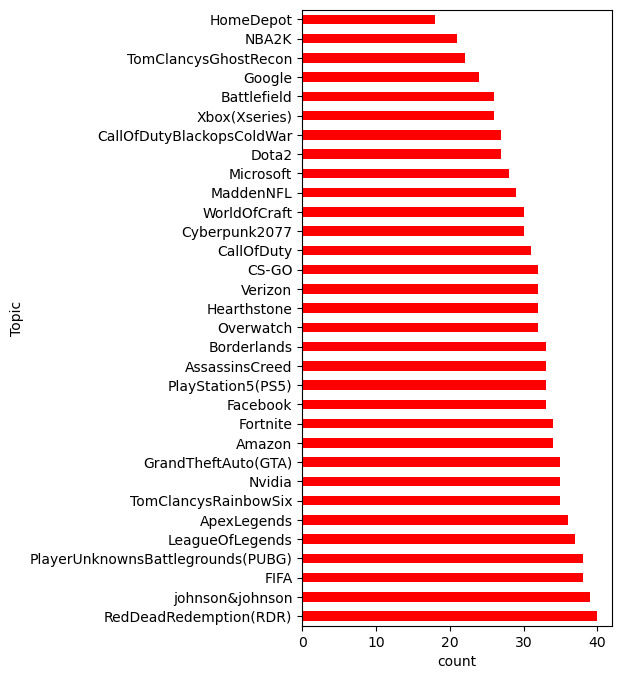

In [35]:
plt.figure(figsize=(4,8))
data['Topic'].value_counts().plot(kind='barh',color='r')
plt.xlabel("count")
plt.show()

SENTIMENT DISTRIBUTION

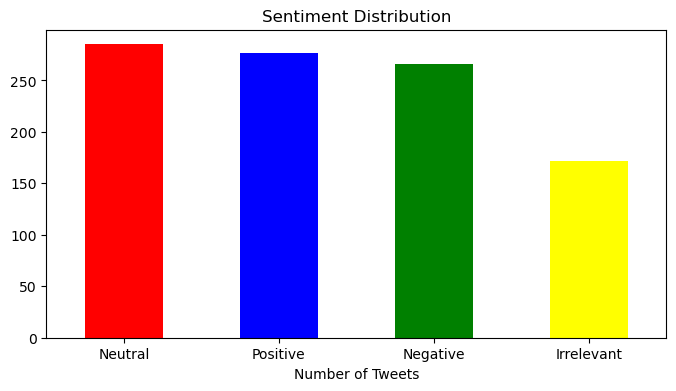

In [37]:
plt.figure(figsize=(8,4))
sentiment_counts.plot(kind='bar',color=['red','blue','green','yellow'])
plt.title('Sentiment Distribution')
plt.xlabel('Number of Tweets')
plt.xticks(rotation=0)
plt.show()

In [41]:
brand_data=data[data['Topic'].str.contains('Microsoft',case=False)]
brand_sentiment_counts=brand_data['Sentiment'].value_counts()
brand_sentiment_counts

Sentiment
Positive      14
Negative       7
Neutral        6
Irrelevant     1
Name: count, dtype: int64

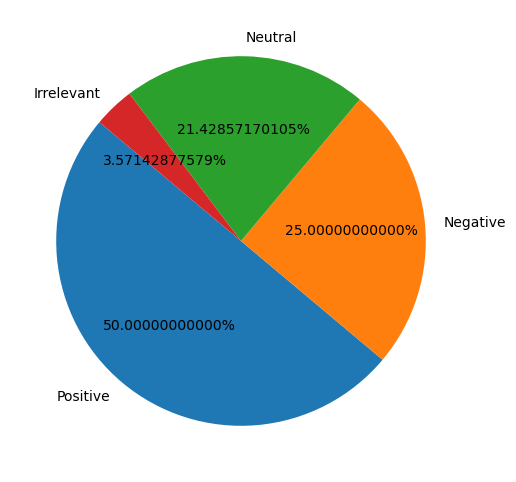

In [44]:
plt.figure(figsize=(6,6))
plt.pie(brand_sentiment_counts,labels=brand_sentiment_counts.index,autopct='%1.11f%%',startangle=140)
plt.show()

OBSERVATION:-

:MOST TOPIC HAS NEGATIVE SENTIMENT

In [45]:
data

,Id,Topic,Sentiment,Text
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...
...,...,...,...,...
995,4891,GrandTheftAuto(GTA),Irrelevant,⭐️ Toronto is the arts and culture capital of ...
996,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
997,2652,Borderlands,Positive,Today sucked so it’s time to drink wine n play...
998,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


SENTIMENT DISTRIBUTION TOPIC-WISE

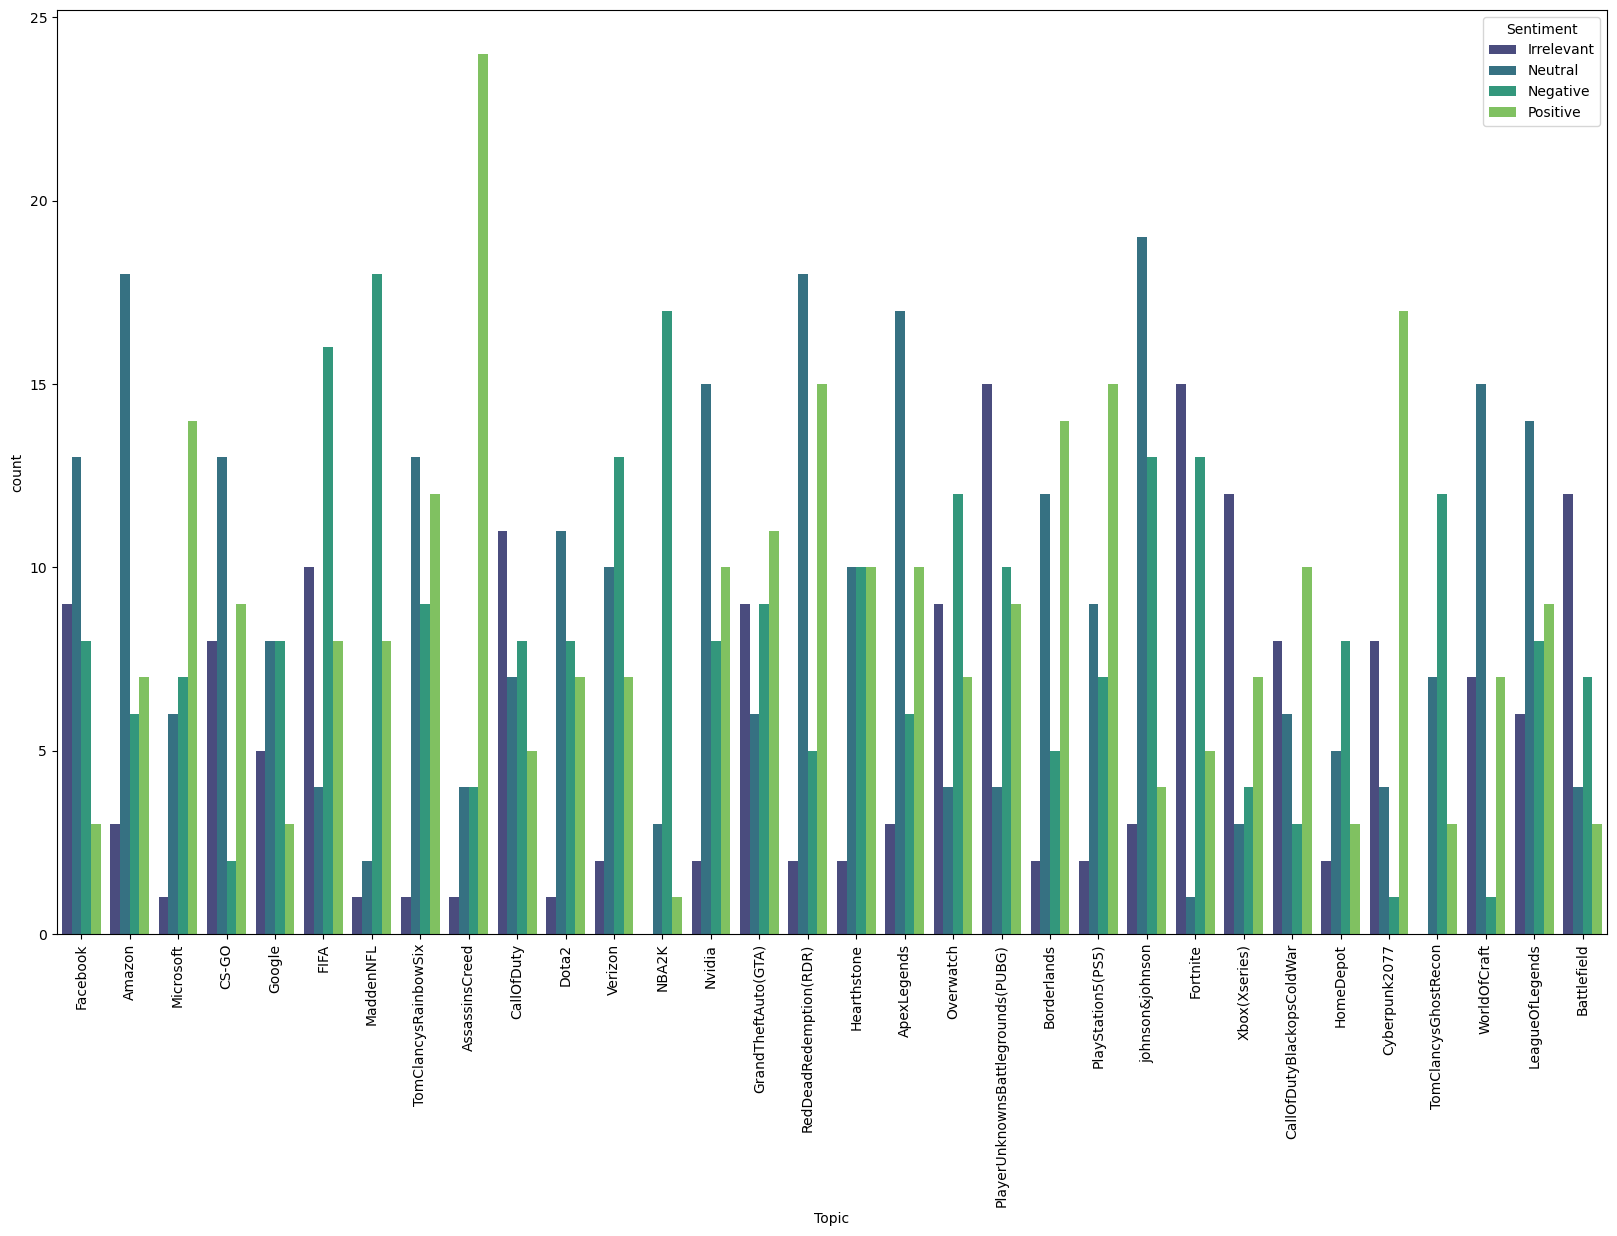

In [48]:
plt.figure(figsize=(20,12))
sns.countplot(x='Topic',data=data,palette='viridis',hue='Sentiment')
plt.xticks(rotation=90)
plt.show()

In [50]:

## Group by Topic and Sentiment
topic_wise_sentiment = data.groupby(["Topic", "Sentiment"]).size().reset_index(name='Count')

# Step 2: Select Top 5 Topics
topic_counts = data['Topic'].value_counts().nlargest(5).index
top_topics_sentiment = topic_wise_sentiment[topic_wise_sentiment['Topic'].isin(topic_counts)]

TOP 5 TOPICS WITH NEGATIVE SENTIMENTS

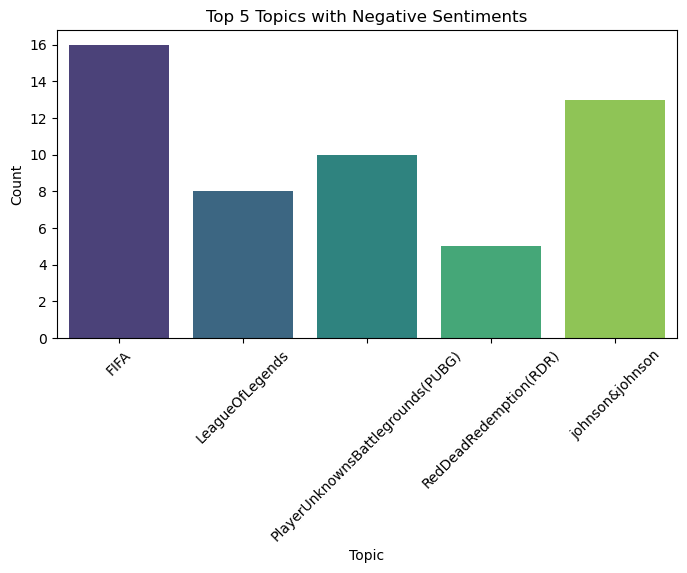

In [51]:

plt.figure(figsize=(8, 4))
sns.barplot(data=top_topics_sentiment[top_topics_sentiment['Sentiment'] == 'Negative'], x='Topic', y='Count', hue='Topic', palette='viridis', legend=False)

plt.title('Top 5 Topics with Negative Sentiments')
plt.xlabel('Topic')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()


TOP 5 TOPICS WITH POSITIVE SENTIMENTS

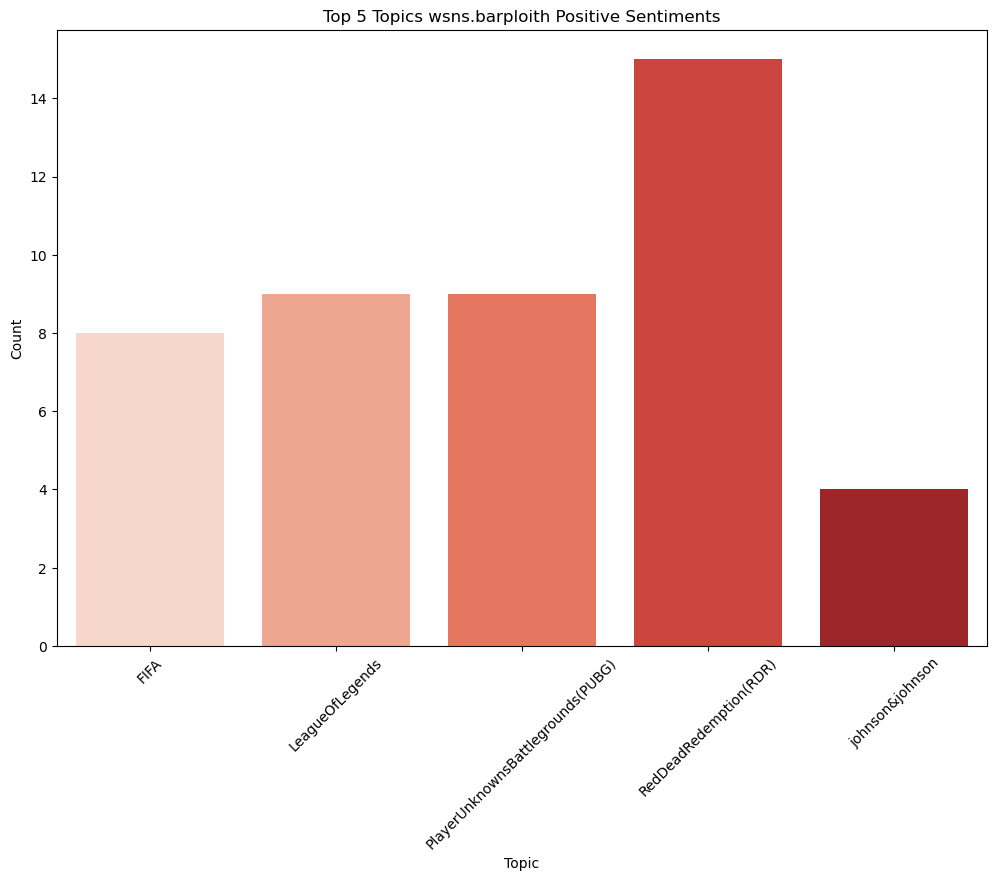

In [52]:
plt.figure(figsize=(12, 8))
sns.barplot(data=top_topics_sentiment[top_topics_sentiment['Sentiment'] == 'Positive'], x='Topic', y='Count', hue='Topic', palette='Reds', legend=False)

plt.title('Top 5 Topics wsns.barploith Positive Sentiments')
plt.xlabel('Topic')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

TOP 5 TOPICS WITH NEUTRAL SENTIMENTS

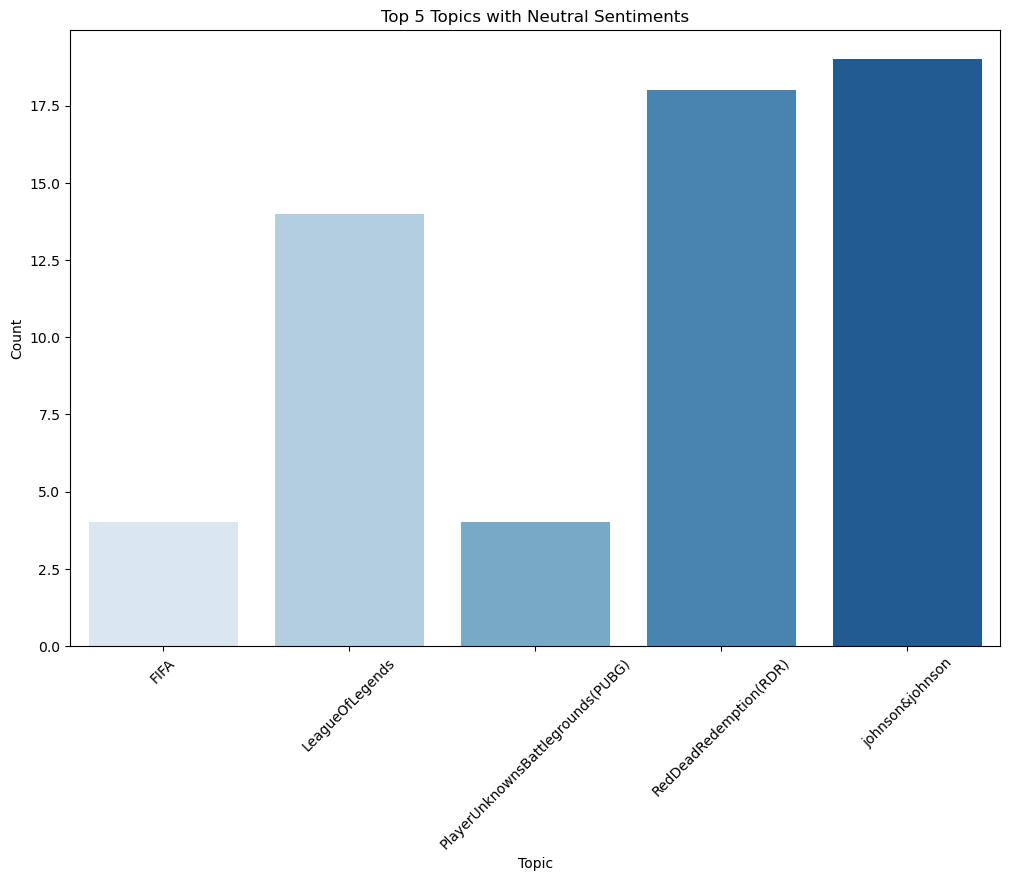

In [53]:

plt.figure(figsize=(12, 8))
sns.barplot(data=top_topics_sentiment[top_topics_sentiment['Sentiment'] == 'Neutral'], x='Topic', y='Count', hue='Topic', palette='Blues', legend=False)

plt.title('Top 5 Topics with Neutral Sentiments')
plt.xlabel('Topic')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

TOP 5 TOPICS WITH IRRELEVANT SENTIMENTS

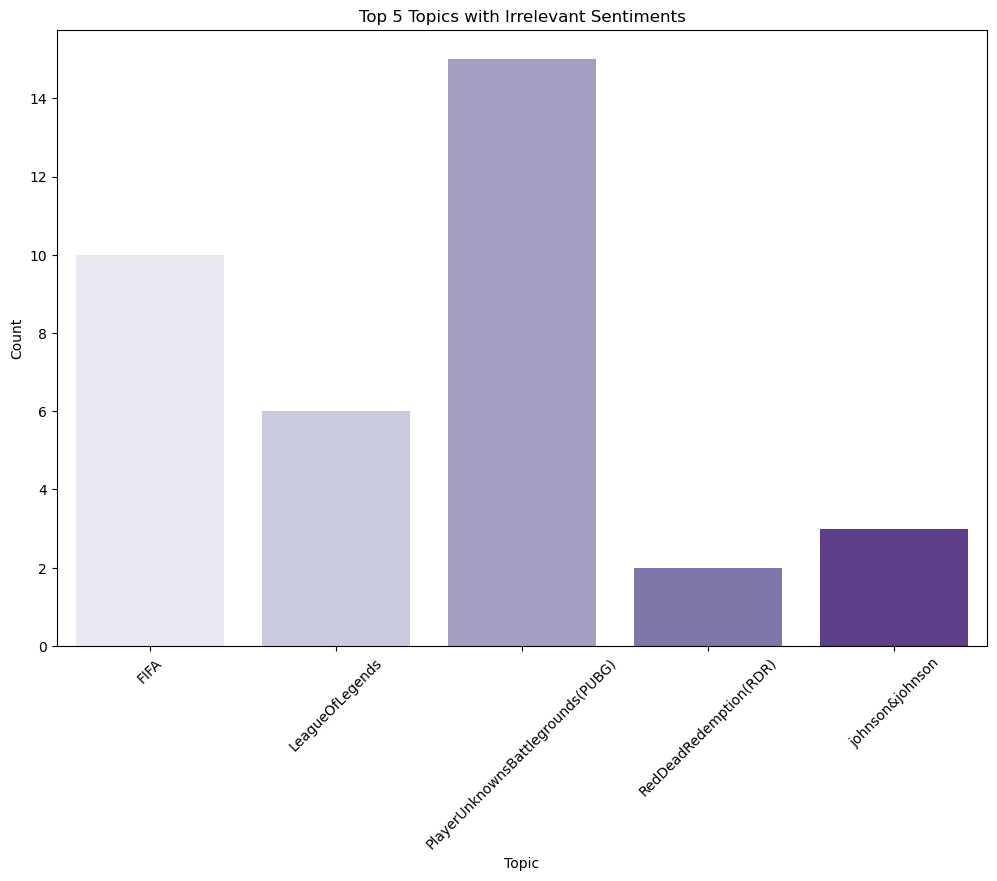

In [54]:

plt.figure(figsize=(12, 8))
sns.barplot(data=top_topics_sentiment[top_topics_sentiment['Sentiment'] == 'Irrelevant'], x='Topic', y='Count', hue='Topic', palette='Purples', legend=False)
plt.title('Top 5 Topics with Irrelevant Sentiments')
plt.xlabel('Topic')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

SENTIMENT DISTRIBUTION OF TOPIC GOOGLE

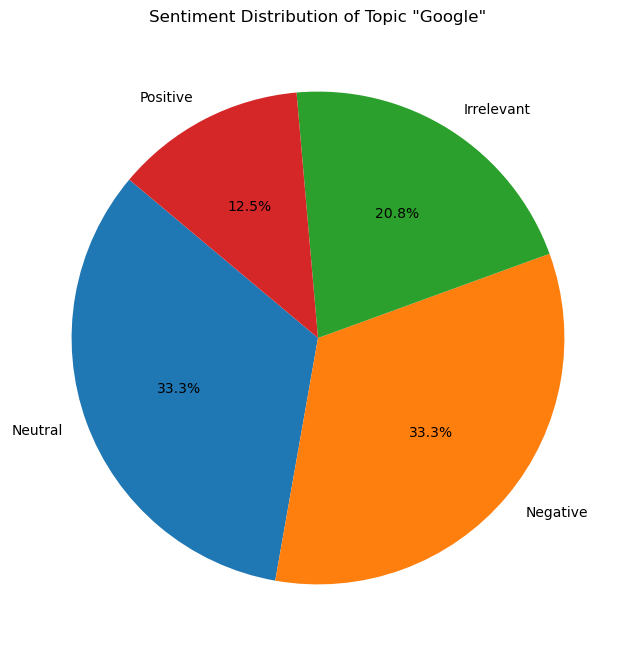

In [55]:

# Filter the dataset to include only entries related to the topic 'Google'
google_data = data[data['Topic'] == 'Google']

# Count the occurrences of each sentiment within the filtered dataset
sentiment_counts = google_data['Sentiment'].value_counts()

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Sentiment Distribution of Topic "Google"')
plt.show()
     

SENTIMENT DISTRIBUTION OF TOPIC MICROSOFT

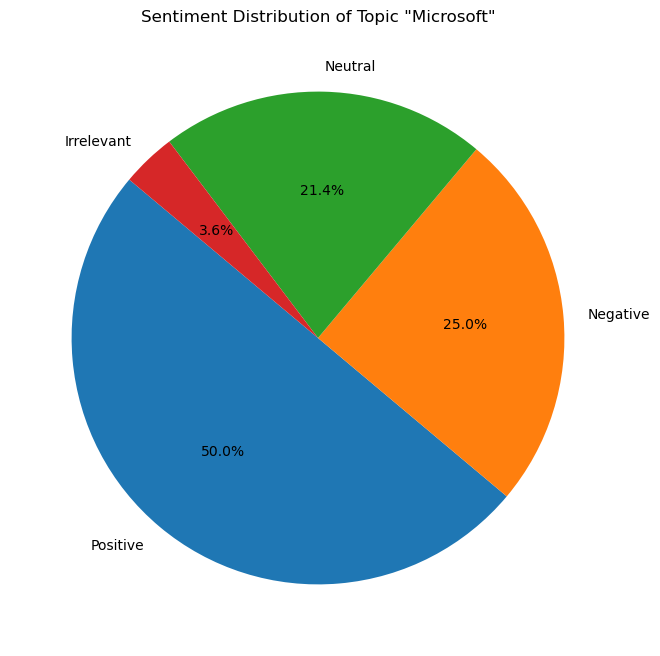

In [56]:
# Filter the dataset to include only entries related to the topic 'Microsoft'
ms_data = data[data['Topic'] == 'Microsoft']

# Count the occurrences of each sentiment within the filtered dataset
sentiment_counts = ms_data['Sentiment'].value_counts()

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Sentiment Distribution of Topic "Microsoft"')
plt.show()

the end